# Module 07, Part 1: Autoencoders and what a bottleneck is forced to learn

This notebook is the runnable companion to Part 1 of the Module 07 learning content.
It checks, with code:

1. An autoencoder is only useful because of its bottleneck. Without one, it can learn to copy.
2. A linear autoencoder with a bottleneck of size $k$ finds the same subspace as PCA with $k$ components.
3. Adding nonlinearity lets the same bottleneck keep more of the image.
4. A denoising autoencoder is a second way to stop an autoencoder from copying.
5. What a two-dimensional code looks like, and why that picture is not yet a generative model.

The data are the 1,797 handwritten digits that ship with scikit-learn: 8 by 8 pixels, scaled to [0, 1],
flattened to 64 numbers. They are small enough that every experiment below runs in seconds on a CPU.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

In [2]:
import numpy as np
import torch
from sklearn.datasets import load_digits


def load_data(seed=0, test_fraction=0.2):
    """Return (X_train, y_train, X_test, y_test). Pixels are scaled to [0, 1] and flattened to 64 values."""
    d = load_digits()
    X = (d.data / 16.0).astype(np.float32)
    y = d.target.astype(np.int64)
    rng = np.random.RandomState(seed)
    idx = rng.permutation(len(X))
    n_test = int(len(X) * test_fraction)
    te, tr = idx[:n_test], idx[n_test:]
    return (torch.tensor(X[tr]), torch.tensor(y[tr]), torch.tensor(X[te]), torch.tensor(y[te]))


def one_hot(y, n=10):
    return torch.nn.functional.one_hot(y, n).float()

In [3]:
class AE(nn.Module):
    """Encoder, bottleneck of size d_latent, decoder. With linear=True there are no hidden layers or activations."""

    def __init__(self, d_in=64, d_hidden=64, d_latent=2, linear=False):
        super().__init__()
        if linear:
            self.enc = nn.Linear(d_in, d_latent)
            self.dec = nn.Linear(d_latent, d_in)
        else:
            self.enc = nn.Sequential(nn.Linear(d_in, d_hidden), nn.ReLU(), nn.Linear(d_hidden, d_latent))
            self.dec = nn.Sequential(nn.Linear(d_latent, d_hidden), nn.ReLU(), nn.Linear(d_hidden, d_in))

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(z)

    def forward(self, x):
        return self.decode(self.encode(x))


def train_ae(model, X, epochs=300, lr=2e-3, batch_size=64, noise=0.0, seed=0):
    """Train with mean squared error. noise > 0 corrupts the input but still rebuilds the clean image (a denoising autoencoder).
    Returns the mean loss of each epoch."""
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for _ in range(epochs):
        perm = torch.randperm(len(X), generator=g)
        total = 0.0
        for i in range(0, len(X), batch_size):
            xb = X[perm[i:i + batch_size]]
            xin = xb + noise * torch.randn(xb.shape, generator=g) if noise > 0 else xb
            loss = ((model(xin) - xb) ** 2).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(xb)
        hist.append(total / len(X))
    return hist


@torch.no_grad()
def reconstruction_mse(model, X):
    return ((model(X) - X) ** 2).mean().item()


def pca_mse(X_train, X_eval, k):
    """Mean squared error of rebuilding X_eval from the top k principal components of X_train."""
    X_train = X_train.numpy().astype(np.float64)
    X_eval = X_eval.numpy().astype(np.float64)
    mu = X_train.mean(0)
    _, _, Vt = np.linalg.svd(X_train - mu, full_matrices=False)
    P = Vt[:k]
    rec = (X_eval - mu) @ P.T @ P + mu
    return float(((rec - X_eval) ** 2).mean())

train (1438, 64) test (359, 64)


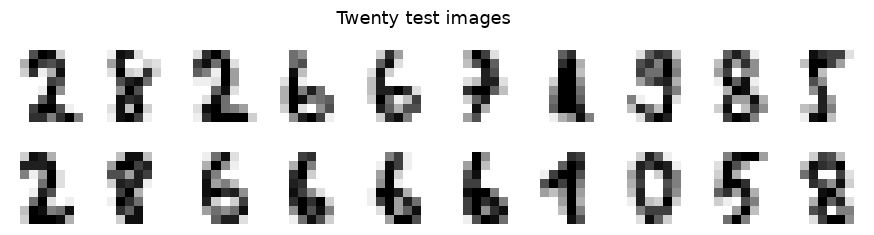

In [4]:
Xtr, ytr, Xte, yte = load_data()
print("train", tuple(Xtr.shape), "test", tuple(Xte.shape))
fig, axes = plt.subplots(2, 10, figsize=(10, 2.2))
for ax, x in zip(axes.ravel(), Xte[:20]):
    ax.imshow(x.reshape(8, 8), cmap="gray_r"); ax.axis("off")
plt.suptitle("Twenty test images", y=1.02); plt.show()

## 1. Why the bottleneck matters

An autoencoder is trained to output its own input, so the "label" is free. If the hidden code is as wide as the input,
nothing stops the network from learning the identity function. A narrow code forces a choice about what to keep.

The experiment trains a linear autoencoder and a one-hidden-layer autoencoder at several code sizes and measures the
reconstruction error on images the model has never seen.

code size   linear AE   MLP AE
        1     0.06348   0.04760
        2     0.05462   0.03395
        4     0.03962   0.02298
        8     0.02542   0.01384
       16     0.01205   0.00735
       32     0.00282   0.00190
       64     0.00001   0.00044


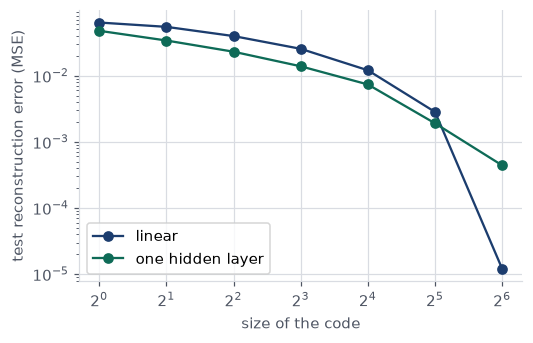

In [5]:
sizes = [1, 2, 4, 8, 16, 32, 64]
lin, mlp = [], []
for k in sizes:
    a = AE(d_latent=k, linear=True); train_ae(a, Xtr, epochs=300, lr=5e-3); lin.append(reconstruction_mse(a, Xte))
    b = AE(d_latent=k); train_ae(b, Xtr, epochs=300); mlp.append(reconstruction_mse(b, Xte))
print("code size   linear AE   MLP AE")
for k, l, m in zip(sizes, lin, mlp):
    print(f"{k:9d}   {l:9.5f}   {m:6.5f}")
fig, ax = plt.subplots(figsize=(5.2, 3.2))
ax.plot(sizes, lin, "o-", color=NAVY, label="linear")
ax.plot(sizes, mlp, "o-", color=GREEN, label="one hidden layer")
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xlabel("size of the code"); ax.set_ylabel("test reconstruction error (MSE)"); ax.legend()
plt.show()

Two things to read from the table. Error falls as the code grows, so a narrow code does lose information. And at a code of
64, the same size as the image, a linear network can reach near-zero error by learning something close to the identity.
Low reconstruction error by itself does not mean the code is a good summary of the image.

## 2. A linear autoencoder finds the PCA subspace

For a linear autoencoder trained with squared error, the best possible solution is known: the decoder spans the top $k$
principal components of the data. We check the claim two ways. First, the errors match. Second, the subspace the decoder
spans is the same subspace PCA finds, measured by the angles between the two.

In [6]:
print("k    linear AE    PCA")
for k in (2, 4, 8, 16):
    a = AE(d_latent=k, linear=True); train_ae(a, Xtr, epochs=400, lr=5e-3)
    print(f"{k:2d}   {reconstruction_mse(a, Xte):.5f}    {pca_mse(Xtr, Xte, k):.5f}")

k = 8
a = AE(d_latent=k, linear=True); train_ae(a, Xtr, epochs=600, lr=5e-3)
W = a.dec.weight.detach().numpy()              # (64, k): the columns span the decoder's subspace
Q, _ = np.linalg.qr(W)
mu = Xtr.numpy().mean(0)
_, _, Vt = np.linalg.svd(Xtr.numpy() - mu, full_matrices=False)
P = Vt[:k].T                                    # (64, k): top k principal directions
cosines = np.linalg.svd(Q.T @ P, compute_uv=False)
print("cosines of the angles between the two subspaces:", np.round(cosines, 3))

k    linear AE    PCA
 2   0.05460    0.05458
 4   0.03954    0.03953
 8   0.02536    0.02532
16   0.01205    0.01196
cosines of the angles between the two subspaces: [1. 1. 1. 1. 1. 1. 1. 1.]


A cosine of 1 means the two directions agree exactly. The autoencoder was never told what a principal component is, yet it
arrives at the same subspace, because that subspace is where the squared error is smallest. The individual code
coordinates are not the principal components themselves. Any invertible mixing of them gives the same reconstruction, so
the autoencoder only fixes the subspace.

## 3. Nonlinearity keeps more

With the same code size, a network with a hidden layer can bend the subspace into a curved surface that follows the data
more closely. In the table above the one-hidden-layer model beats the linear one at every code size below 64. For a
two-dimensional code, the difference is the picture below: the same eight test digits, rebuilt by PCA with two components
and by the nonlinear autoencoder with a two-dimensional code.

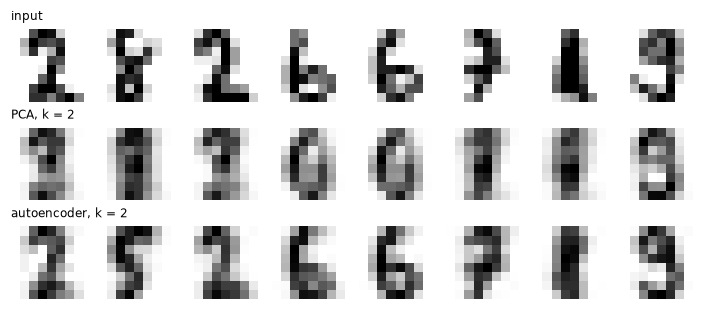

test MSE, k = 2:  PCA 0.05458   autoencoder 0.03748


In [7]:
a2 = AE(d_latent=2); train_ae(a2, Xtr, epochs=300)
Xe = Xte[:8].numpy().astype(np.float64)
Xtr_np = Xtr.numpy().astype(np.float64); mu = Xtr_np.mean(0)
_, _, Vt = np.linalg.svd(Xtr_np - mu, full_matrices=False)
pca_rec = (Xe - mu) @ Vt[:2].T @ Vt[:2] + mu
with torch.no_grad():
    ae_rec = a2(Xte[:8]).numpy()
fig, axes = plt.subplots(3, 8, figsize=(8, 3.3))
for j in range(8):
    for i, (img, name) in enumerate([(Xe[j], "input"), (pca_rec[j], "PCA, k = 2"), (ae_rec[j], "autoencoder, k = 2")]):
        axes[i, j].imshow(np.clip(img, 0, 1).reshape(8, 8), cmap="gray_r"); axes[i, j].axis("off")
        if j == 0: axes[i, j].set_title(name, fontsize=8, loc="left")
plt.show()
print("test MSE, k = 2:  PCA", round(pca_mse(Xtr, Xte, 2), 5), "  autoencoder", round(reconstruction_mse(a2, Xte), 5))

## 4. Denoising: a second way to stop copying

A bottleneck is one way to prevent the identity solution. Another is to corrupt the input and ask for the clean image. If
the network simply copies, it copies the noise and is penalized. We compare two wide autoencoders, both with a code of
size 64 (no bottleneck at all), one trained to copy and one trained to denoise, on test images with noise added.

error of the noisy input itself : 0.0891
plain autoencoder, noisy input  : 0.0627
denoising autoencoder           : 0.0170


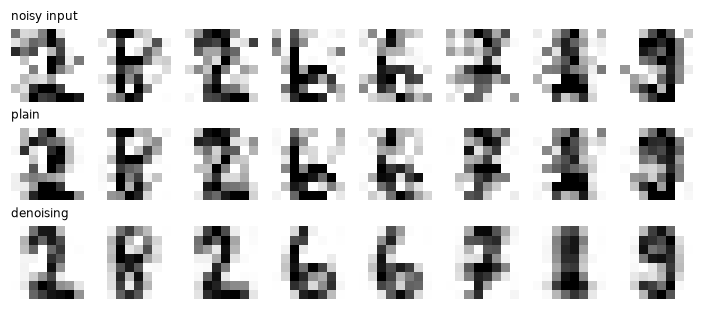

In [8]:
torch.manual_seed(0)
plain = AE(d_hidden=128, d_latent=64); train_ae(plain, Xtr, epochs=200)
denoise = AE(d_hidden=128, d_latent=64); train_ae(denoise, Xtr, epochs=200, noise=0.3)
g = torch.Generator().manual_seed(5)
noisy = Xte + 0.3 * torch.randn(Xte.shape, generator=g)
with torch.no_grad():
    mse_noisy_input = ((noisy - Xte) ** 2).mean().item()
    mse_plain = ((plain(noisy) - Xte) ** 2).mean().item()
    mse_denoise = ((denoise(noisy) - Xte) ** 2).mean().item()
print(f"error of the noisy input itself : {mse_noisy_input:.4f}")
print(f"plain autoencoder, noisy input  : {mse_plain:.4f}")
print(f"denoising autoencoder           : {mse_denoise:.4f}")
fig, axes = plt.subplots(3, 8, figsize=(8, 3.3))
with torch.no_grad():
    outs = [Xte[:8], noisy[:8], plain(noisy[:8]), denoise(noisy[:8])]
for j in range(8):
    for i, (img, name) in enumerate([(noisy[j], "noisy input"), (plain(noisy[j:j+1])[0].detach(), "plain"), (denoise(noisy[j:j+1])[0].detach(), "denoising")]):
        axes[i, j].imshow(img.clamp(0, 1).reshape(8, 8), cmap="gray_r"); axes[i, j].axis("off")
        if j == 0: axes[i, j].set_title(name, fontsize=8, loc="left")
plt.show()

The plain autoencoder passes much of the noise through, so its error stays several times higher than the denoising model's. The
denoising autoencoder has to find structure in the data to tell signal from noise. Both are ways to force
an autoencoder to learn something. Neither of them makes it a model you can sample from, which is the subject of Part 2.

## 5. A two-dimensional code

With a code of size 2 we can plot every test image as a point, coloured by its digit.

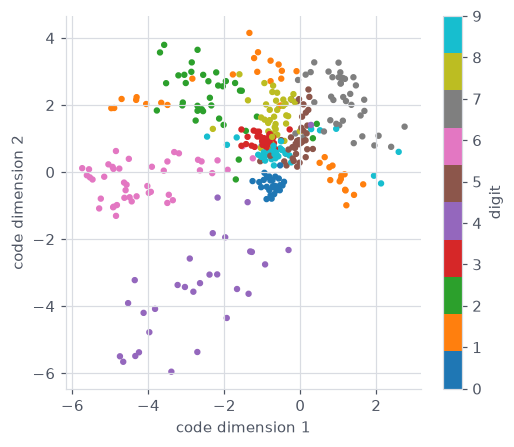

code mean per dimension : [-1.22  0.7 ]
code std per dimension  : [1.78 1.71]
code range per dimension: [-5.7 -6. ] to [2.7 4.2]


In [9]:
a2 = AE(d_latent=2); train_ae(a2, Xtr, epochs=400)
with torch.no_grad():
    z = a2.encode(Xte).numpy()
fig, ax = plt.subplots(figsize=(5.2, 4.4))
sc = ax.scatter(z[:, 0], z[:, 1], c=yte.numpy(), cmap="tab10", s=10)
ax.set_xlabel("code dimension 1"); ax.set_ylabel("code dimension 2"); plt.colorbar(sc, label="digit"); plt.show()
print("code mean per dimension :", np.round(z.mean(0), 2))
print("code std per dimension  :", np.round(z.std(0), 2))
print("code range per dimension:", np.round(z.min(0), 1), "to", np.round(z.max(0), 1))

Digits of the same class sit near each other, so the encoder has found structure without ever seeing a label. But look at what
the picture does not give you: the codes occupy an irregular region of arbitrary size and centre, with gaps between clusters.
If you wanted to invent a new image by picking a code, you would have no rule for which codes are valid. Part 2 turns this
into a measurement and fixes it.

## What to take away

- The bottleneck, or some other restriction such as noise, is what makes an autoencoder learn anything. The reconstruction
  error alone does not tell you whether the code is useful.
- A linear autoencoder recovers the PCA subspace. A nonlinear one can do better at the same code size.
- An autoencoder gives you a code for each existing image. It does not give you a way to generate new ones.